# Task 4 – Voiceprint Verification Model (Training)

**Owner:** Santhiana (audio pipeline and features) · Peggy (model training)
**Reads:** `data/audio/processed/audio_features.csv` (made by `src/audio_pipeline.py`)
**Writes:** `models/voice_model.joblib`

**Goal:** given a recording, say **which team member** it belongs to, *or* say **"unknown"** if it doesn't clearly match anyone. The second part is what makes the **unauthorized attempt** fail.

**Scores we track** (same as the product model, so all three models are compared the same way):
- **Accuracy:** the share of correct guesses. Guessing at random gives 33% with the 3 members currently enrolled (25% once all 4 are in).
- **F1-score (macro):** accuracy that treats every member fairly.
- **Loss (log loss):** how confident-and-wrong the model is. Lower is better. Random guessing gives 1.10 (ln 3) with 3 members, or 1.39 (ln 4) with 4.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))   # reuse the project code in src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config as C

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
import joblib
from sklearn.metrics import ConfusionMatrixDisplay
from identity_model import train_identity_model, save_bundle, identify, feature_columns
from audio_pipeline import audio_to_features

# audio_pipeline.py names the columns speaker / utterance / variant / filename;
# rename them to the shared names used by identity_model.py (same as the face model)
df = (pd.read_csv(C.AUDIO_FEATURES_CSV)
        .rename(columns={"speaker": "member", "utterance": "source_file", "variant": "augmentation"})
        .drop(columns=["filename"]))
print(df.shape)
df.iloc[:, :8].head()

(36, 37)


,member,source_file,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean
0,peggy,peggy_confirm_transaction,clean,-167.887085,70.681374,103.426926,44.836658,5.842264
1,peggy,peggy_confirm_transaction,pitch_up,-150.908722,70.547203,97.926712,42.707348,3.854378
2,peggy,peggy_confirm_transaction,pitch_down,-154.094635,73.073586,108.213242,41.139084,0.883072
3,peggy,peggy_confirm_transaction,faster,-163.687271,74.784943,99.133034,43.203266,6.480505
4,peggy,peggy_confirm_transaction,slower,-148.402176,72.357964,97.609482,43.352867,6.249029


In [2]:
print("Rows per member:"); print(df.member.value_counts().to_string())
print("\nOriginal recordings per member:"); print(df.groupby("member")["source_file"].nunique().to_string())
print("\nFeatures:", len(feature_columns(df)), "| missing values:", df.isna().sum().sum())

Rows per member:
member
peggy        12
santhiana    12
shema        12

Original recordings per member:
member
peggy        2
santhiana    2
shema        2

Features: 34 | missing values: 0


**Result:** 12 rows per member, from **only 2 original recordings each** (6 in total), with 34 features and no missing values.

With 2 recordings per member, cross-validation uses **2 folds**. Each fold trains on one phrase and tests on the *other* phrase. That's a hard test: the model must recognise a voice saying words it never heard from that person.

## 1. A fair test: split by original recording

Every recording appears 6 times in the table (the clean original plus its 5 augmented copies).
- **If we split rows at random**, a flipped copy could land in training while the original lands in testing. The model would effectively have seen the answer, and the score would look much better than it really is.
- **So we split by `source_file`** using `StratifiedGroupKFold`: every copy of one recording always stays on the same side, and each fold still contains every member.

This is the same idea the product model uses when it splits by customer.

The number of folds equals the smallest number of original recordings any member has. Each fold therefore tests one unseen recording per member.

## 2. Compare two models and pick the best

| Model | Why we try it |
|---|---|
| **Logistic Regression** (with standard scaling) | Simple, fast, and gives well-calibrated probabilities, which matters for the confidence threshold. |
| **Random Forest** (300 trees, at least 2 rows per leaf) | Handles non-linear patterns and needs no scaling. The leaf limit stops it from memorising single rows. |

The model with the best cross-validated **F1** wins. If the F1 scores tie, the lower **loss** wins.

In [3]:
bundle = train_identity_model(df, group_col="source_file")

Rows: 36 from 6 original files | 2-fold grouped CV
              model  accuracy  f1_macro  log_loss
      Random Forest     0.556     0.563     0.836
Logistic Regression     0.556     0.543     1.016

Chosen: Random Forest
  CV    -> acc 0.56 | F1 0.56 | loss 0.84
  Train -> acc 1.00 | F1 1.00 | loss 0.12
  Confidence threshold: 0.41
  CV genuine attempts accepted: 22% | accepted as the WRONG member: 36%


**Result:** both models reach the same accuracy (0.56). **Random Forest is chosen on its higher F1** (0.56 vs 0.54) and lower loss (0.84 vs 1.02). With 3 members, chance accuracy is 0.33, so the model learns something, but far less than the face model (0.93).

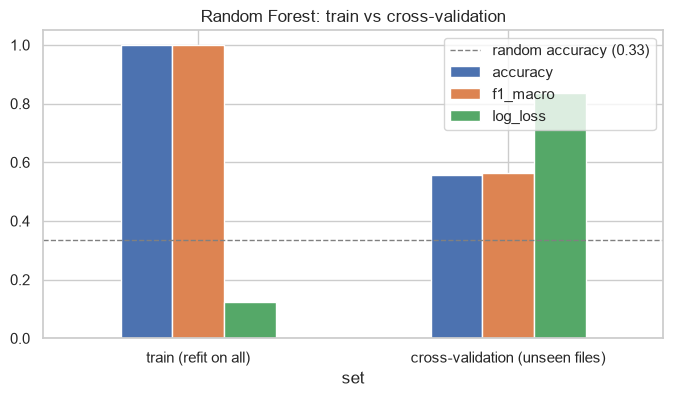

,accuracy,f1_macro,log_loss
set,,,
train (refit on all),1.000,1.000,0.123
cross-validation (unseen files),0.556,0.563,0.836


In [4]:
b = bundle
summary = pd.DataFrame([{"set": "train (refit on all)", **b["train_scores"]},
                        {"set": "cross-validation (unseen files)", **b["cv_scores"]}]).set_index("set")
ax = summary.plot(kind="bar", figsize=(8, 4), rot=0)
chance = 1 / len(b["classes"])
ax.axhline(chance, color="grey", ls="--", lw=1, label=f"random accuracy ({chance:.2f})")
ax.set_title(f"{b['model_name']}: train vs cross-validation"); ax.legend(loc="upper right"); plt.show()
summary.round(3)

**This model is overfitting.**
- **On its training clips** it's perfect: accuracy 1.00, loss 0.12.
- **On a recording it hasn't heard** it drops to 0.56 accuracy and 0.84 loss.
- **The cause is too few examples:** only 6 truly different recordings. The 5 augmented copies of each clip are variations of the same take, not new examples of a person's voice, so the model memorises the clips instead of learning the voices.

**How to read it:**
- The **train** scores come from the model refit on every row, so they are optimistic.
- The **cross-validation** scores come from recordings the model never saw, and these are the honest numbers.
- A big gap between the two (for example 1.00 train vs 0.70 CV) means the model memorises. A small gap means it generalises.

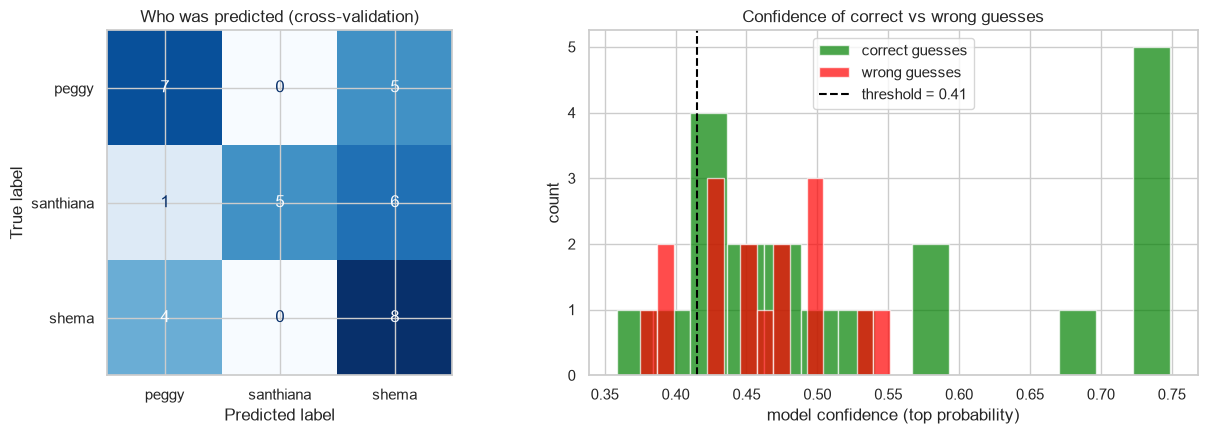

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay(b["confusion"], display_labels=sorted(df.member.unique())).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Who was predicted (cross-validation)")

conf = b["oof_proba"].max(1)
pred = np.array(sorted(df.member.unique()))[b["oof_proba"].argmax(1)]
right = pred == b["oof_true"]
axes[1].hist(conf[right], bins=15, alpha=0.7, label="correct guesses", color="green")
axes[1].hist(conf[~right], bins=15, alpha=0.7, label="wrong guesses", color="red")
axes[1].axvline(b["threshold"], color="black", ls="--", label=f"threshold = {b['threshold']:.2f}")
axes[1].set_xlabel("model confidence (top probability)"); axes[1].set_ylabel("count")
axes[1].set_title("Confidence of correct vs wrong guesses"); axes[1].legend()
plt.tight_layout(); plt.show()

**What it shows:**
- **Predictions lean towards Shema.** Santhiana's recordings are called Shema 6 times out of 12, and only 5 are correct. Peggy's are 7/12 correct, Shema's 8/12.
- **Confidence (right):** correct and wrong guesses fall in the same range (0.35–0.75). No threshold can separate them, which is why some wrong guesses get through.
- **Possible confound:** each member recorded on a different device and format (Peggy 48 kHz WAV with background hiss, Shema 44.1 kHz MP3, Santhiana 16 kHz WAV). Everything is resampled to 16 kHz, but differences in noise and microphone remain. With this little data, the model may partly learn the recording setup rather than the voice.

## 3. Decision rule: when do we say "unknown"?

A normal classifier **always** picks one of the 4 members, even for a stranger. To be able to say *no*, the system uses two checks:

1. **Confidence threshold:** the model's top probability must be at least the threshold.
   - The threshold is set automatically to the confidence reached by **90% of correct** cross-validation guesses. In other words, we accept about 90% of genuine attempts.
   - It is kept between 0.40 and 0.85.
   - In the right-hand histogram, the wrong guesses (red) should mostly fall to the left of the dashed line, which means they get rejected.
2. **Novelty check (Local Outlier Factor):** this asks whether the input looks like *anything* in the training data. A stranger's recording sits far from every member's points, so it's flagged even if the classifier happens to be confident.

Access is granted only when both checks pass.

In [6]:
print(f"Genuine attempts accepted (cross-validation): {b['genuine_accept_rate']:.0%}")
print(f"Accepted as the WRONG member               : {b['wrong_member_accept_rate']:.0%}")
print(f"Flagged as 'unknown' by the novelty check   : {b['oof_novel'].mean():.0%} of genuine attempts")

Genuine attempts accepted (cross-validation): 22%
Accepted as the WRONG member               : 36%
Flagged as 'unknown' by the novelty check   : 28% of genuine attempts


**Result:**
- **22% of genuine attempts are accepted.** Most real users would be asked to try again.
- **36% are accepted as the wrong member.** On its own, this voice check is not safe.

In the full system it works only as a second factor: the voice must match the member that the much stronger face model already recognised, and a wrong-member voice is denied.

## 4. Unauthorized attempt: a non-member must be rejected

In [7]:
files = [p for p in sorted(C.AUDIO_UNAUTH_DIR.glob("*")) if p.suffix.lower() in C.AUDIO_EXTS]
if not files:
    print("No file in", C.AUDIO_UNAUTH_DIR, "- add a non-member sample (or run: python src/make_unauthorized_samples.py)")
for p in files:
    r = identify(b, audio_to_features(p))
    print(f"{p.name}: {'ACCEPTED as ' + r['member'] if r['accepted'] else 'REJECTED'}  ->  {r['reason']}")
    print("   probabilities:", r["probabilities"])

stranger_synthetic.wav: REJECTED  ->  input does not look like any enrolled team member (novelty check)
   probabilities: {'peggy': np.float64(0.154), 'santhiana': np.float64(0.346), 'shema': np.float64(0.5)}


**Result:** the stranger recording is **rejected by the novelty check**. The classifier alone leaned towards Shema (0.50), which is above the 0.41 threshold, so without the novelty check it would have been accepted.

## 4b. Can regularisation fix the overfitting?

We try a weaker and a stronger limit on each model type and compare the same metrics.

In [8]:
# Does stronger regularisation reduce the overfitting? Same grouped CV as above.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from identity_model import cross_validate_model, scores, choose_threshold

X, y, g = df[feature_columns(df)], df["member"], df["source_file"]
cls = sorted(y.unique())
candidates = {
    "Logistic Regression, C=1 (weak limit)": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)),
    "Logistic Regression, C=0.01 (strong limit)": make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=5000)),
    "Random Forest, unlimited depth (used)": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=42),
    "Random Forest, depth 2, 6 rows per leaf": RandomForestClassifier(n_estimators=300, max_depth=2, min_samples_leaf=6, random_state=42),
}
rows = []
for name, model in candidates.items():
    p, novel = cross_validate_model(model, X, y, g, cls)
    cv, tr = scores(y, p, cls), scores(y, model.fit(X, y).predict_proba(X), cls)
    thr, pred = choose_threshold(y, p, cls), np.array(cls)[p.argmax(1)]
    ok = (p.max(1) >= thr) & ~novel
    rows.append({"setting": name, "train loss": tr["log_loss"], "CV loss": cv["log_loss"], "CV accuracy": cv["accuracy"],
                 "genuine accepted": np.mean(ok & (pred == y.values)), "wrong member accepted": np.mean(ok & (pred != y.values))})
pd.DataFrame(rows).set_index("setting").round(2)

,train loss,CV loss,CV accuracy,genuine accepted,wrong member accepted
setting,,,,,
"Logistic Regression, C=1 (weak limit)",0.03,1.02,0.56,0.31,0.42
"Logistic Regression, C=0.01 (strong limit)",0.55,0.89,0.50,0.28,0.36
"Random Forest, unlimited depth (used)",0.12,0.84,0.56,0.22,0.36
"Random Forest, depth 2, 6 rows per leaf",0.29,1.00,0.72,0.06,0.00


**Result:** regularisation **narrows the gap but doesn't fix the model**.
- **Strong limit on Logistic Regression:** the train/CV loss gap falls from 0.99 to 0.34, but CV accuracy drops to 0.50.
- **Most constrained forest:** best CV accuracy (0.72), and it never accepts the wrong member. But it's so unsure that only 6% of genuine attempts would pass.

Every setting just trades memorisation for under-confidence. **The limit is the data, not the model settings.** The fix is 3–5 takes of each phrase per member, recorded on the same kind of device. We keep the unlimited Random Forest because it is the most usable in the demo.

## 5. Save the model

In [9]:
save_bundle(b, C.VOICE_MODEL_PATH)
print("Saved:", C.VOICE_MODEL_PATH, "| keys:", list(joblib.load(C.VOICE_MODEL_PATH).keys()))

Saved: C:\Users\PeggyDusenge\Desktop\U\UserIdentityandProductRecommendationSystem\models\voice_model.joblib | keys: ['model', 'novelty', 'features', 'classes', 'threshold', 'model_name', 'cv_scores', 'train_scores', 'genuine_accept_rate', 'wrong_member_accept_rate']


## Summary
- **Validation:** grouped by original recording, so augmented copies never leak into the test fold.
- **Model choice:** Random Forest (CV accuracy 0.56, F1 0.56, loss 0.84) chosen over Logistic Regression on F1.
- **Overfitting:** clear (train accuracy 1.00 vs CV 0.56). Regularisation does not fix it (section 4b); more recordings would.
- **Safety:** 36% of wrong-member attempts pass this check on its own, so the system relies on the voice matching the face.
- **Stranger:** rejected by the novelty check.
- **Metrics reported:** accuracy, F1, loss (train vs CV) and a confusion matrix.
- **Rejecting strangers:** the confidence threshold plus the novelty check let the model answer *"unknown"*, which the command-line app uses to deny access.
- **Saved to:** `models/voice_model.joblib`, which `app/cli.py` loads.

The same steps can be run without Jupyter: `python src/train_voice_model.py --rebuild`.